In [ ]:
#For Google Drive
#from google.colab import drive
#from pathlib import Path

#drive.mount('/content/drive')

In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
# Setting dataset path
SICAP_ROOT = Path("/kaggle/input/sicapv2/SICAPv2/SICAPv2")  # Kaggle
#SICAP_ROOT = Path("/content/drive/MyDrive/VIT/Images/SICAPv2")   # Colab

IMAGES_DIR = SICAP_ROOT / "images"
PARTITION_DIR = SICAP_ROOT / "partition" / "Test"
VALIDATION_DIR = SICAP_ROOT / "partition" / "Validation"

print("Images dir:", IMAGES_DIR)
print("Partition dir:", PARTITION_DIR)

print("SICAP_ROOT exists:", SICAP_ROOT.exists())
!ls "{SICAP_ROOT}"

Images dir: /kaggle/input/sicapv2/SICAPv2/SICAPv2/images
Partition dir: /kaggle/input/sicapv2/SICAPv2/SICAPv2/partition/Test
SICAP_ROOT exists: True
images	masks  partition  readme.txt  wsi_labels.xlsx


In [ ]:
# Loading dataset
import pandas as pd

train_xlsx_path = PARTITION_DIR / "Train.xlsx"
test_xlsx_path  = PARTITION_DIR / "Test.xlsx"
validation_xlsx_path = VALIDATION_DIR / "Val1/Validation.xlsx"

print("Train xlsx path:", train_xlsx_path)
print("Test  xlsx path:", test_xlsx_path)

train_df = pd.read_excel(train_xlsx_path)
test_df  = pd.read_excel(test_xlsx_path)

print("Train_df shape:", train_df.shape)
print("Test_df shape:", test_df.shape)
train_df.head()

Train xlsx path: /kaggle/input/sicapv2/SICAPv2/SICAPv2/partition/Test/Train.xlsx
Test  xlsx path: /kaggle/input/sicapv2/SICAPv2/SICAPv2/partition/Test/Test.xlsx
Train_df shape: (9959, 6)
Test_df shape: (2122, 6)


,image_name,NC,G3,G4,G5,G4C
0,16B0001851_Block_Region_1_0_0_xini_6803_yini_5...,0,0,0,1,0
1,16B0001851_Block_Region_1_0_1_xini_7827_yini_5...,0,0,0,1,0
2,16B0001851_Block_Region_1_0_2_xini_8851_yini_5...,0,0,0,1,0
3,16B0001851_Block_Region_1_0_3_xini_9875_yini_5...,0,0,0,1,0
4,16B0001851_Block_Region_1_1_0_xini_6803_yini_6...,0,0,0,1,0


In [ ]:
# Add image paths to dataset
train_df["path"] = train_df.image_name.apply(lambda x: f"{IMAGES_DIR}/{x}")
test_df["path"] = test_df.image_name.apply(lambda x: f"{IMAGES_DIR}/{x}")

In [ ]:
train_df.columns

Index(['image_name', 'NC', 'G3', 'G4', 'G5', 'G4C', 'path'], dtype='object')

In [ ]:
train_df.head()

,image_name,NC,G3,G4,G5,G4C,path
0,16B0001851_Block_Region_1_0_0_xini_6803_yini_5...,0,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
1,16B0001851_Block_Region_1_0_1_xini_7827_yini_5...,0,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
2,16B0001851_Block_Region_1_0_2_xini_8851_yini_5...,0,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
3,16B0001851_Block_Region_1_0_3_xini_9875_yini_5...,0,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
4,16B0001851_Block_Region_1_1_0_xini_6803_yini_6...,0,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...


In [ ]:
test_df.head()

,image_name,NC,G3,G4,G5,G4C,path
0,16B0003388_Block_Region_13_10_1_xini_8636_yini...,0,0,1,0,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
1,16B0003388_Block_Region_13_10_2_xini_9660_yini...,0,0,1,0,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
2,16B0003388_Block_Region_13_10_3_xini_10684_yin...,0,0,1,0,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
3,16B0003388_Block_Region_13_11_1_xini_8636_yini...,0,0,1,0,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
4,16B0003388_Block_Region_13_11_2_xini_9660_yini...,0,0,1,0,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...


In [ ]:
train_df = train_df.drop(["G4C"], axis=1)
test_df = test_df.drop(["G4C"], axis=1)

In [ ]:
train_df.head()

,image_name,NC,G3,G4,G5,path
0,16B0001851_Block_Region_1_0_0_xini_6803_yini_5...,0,0,0,1,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
1,16B0001851_Block_Region_1_0_1_xini_7827_yini_5...,0,0,0,1,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
2,16B0001851_Block_Region_1_0_2_xini_8851_yini_5...,0,0,0,1,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
3,16B0001851_Block_Region_1_0_3_xini_9875_yini_5...,0,0,0,1,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
4,16B0001851_Block_Region_1_1_0_xini_6803_yini_6...,0,0,0,1,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...


In [ ]:
test_df.head()

,image_name,NC,G3,G4,G5,path
0,16B0003388_Block_Region_13_10_1_xini_8636_yini...,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
1,16B0003388_Block_Region_13_10_2_xini_9660_yini...,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
2,16B0003388_Block_Region_13_10_3_xini_10684_yin...,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
3,16B0003388_Block_Region_13_11_1_xini_8636_yini...,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...
4,16B0003388_Block_Region_13_11_2_xini_9660_yini...,0,0,1,0,/kaggle/input/sicapv2/SICAPv2/SICAPv2/images/1...


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
labels = ["NC", "G3", "G4", "G5"]
y_true_labels = np.argmax(train_df[labels].values, axis=1)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    stratify=y_true_labels,
    random_state=42,
)

print("Train_df shape:", train_df.shape)
print("Val_df shape:", val_df.shape)
print("Test_df shape:", test_df.shape)

Train_df shape: (7967, 6)
Val_df shape: (1992, 6)
Test_df shape: (2122, 6)


In [ ]:
for label in labels:
    print(f"\nTrain_df Distribution - {label}:")
    display(train_df[label].value_counts())


Train_df Distribution - NC:


NC
0    4949
1    3018
Name: count, dtype: int64


Train_df Distribution - G3:


G3
0    6504
1    1463
Name: count, dtype: int64


Train_df Distribution - G4:


G4
0    5054
1    2913
Name: count, dtype: int64


Train_df Distribution - G5:


G5
0    7394
1     573
Name: count, dtype: int64

In [ ]:
for label in labels:
    print(f"\nVal_df Distribution - {label}:")
    display(val_df[label].value_counts())


Val_df Distribution - NC:


NC
0    1237
1     755
Name: count, dtype: int64


Val_df Distribution - G3:


G3
0    1626
1     366
Name: count, dtype: int64


Val_df Distribution - G4:


G4
0    1264
1     728
Name: count, dtype: int64


Val_df Distribution - G5:


G5
0    1849
1     143
Name: count, dtype: int64

In [ ]:
for label in labels:
    print(f"\nTest_df Distribution - {label}:")
    display(test_df[label].value_counts())


Test_df Distribution - NC:


NC
0    1478
1     644
Name: count, dtype: int64


Test_df Distribution - G3:


G3
0    1729
1     393
Name: count, dtype: int64


Test_df Distribution - G4:


G4
0    1269
1     853
Name: count, dtype: int64


Test_df Distribution - G5:


G5
0    1890
1     232
Name: count, dtype: int64

In [ ]:
import torch
import torchvision
import timm
from PIL import Image

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [ ]:
timm.list_models("swin*",pretrained=True)

['swin_base_patch4_window7_224.ms_in1k',
 'swin_base_patch4_window7_224.ms_in22k',
 'swin_base_patch4_window7_224.ms_in22k_ft_in1k',
 'swin_base_patch4_window12_384.ms_in1k',
 'swin_base_patch4_window12_384.ms_in22k',
 'swin_base_patch4_window12_384.ms_in22k_ft_in1k',
 'swin_large_patch4_window7_224.ms_in22k',
 'swin_large_patch4_window7_224.ms_in22k_ft_in1k',
 'swin_large_patch4_window12_384.ms_in22k',
 'swin_large_patch4_window12_384.ms_in22k_ft_in1k',
 'swin_s3_base_224.ms_in1k',
 'swin_s3_small_224.ms_in1k',
 'swin_s3_tiny_224.ms_in1k',
 'swin_small_patch4_window7_224.ms_in1k',
 'swin_small_patch4_window7_224.ms_in22k',
 'swin_small_patch4_window7_224.ms_in22k_ft_in1k',
 'swin_tiny_patch4_window7_224.ms_in1k',
 'swin_tiny_patch4_window7_224.ms_in22k',
 'swin_tiny_patch4_window7_224.ms_in22k_ft_in1k',
 'swinv2_base_window8_256.ms_in1k',
 'swinv2_base_window12_192.ms_in22k',
 'swinv2_base_window12to16_192to256.ms_in22k_ft_in1k',
 'swinv2_base_window12to24_192to384.ms_in22k_ft_in1k',


In [ ]:
from torchvision import transforms as T
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = T.Compose([
    T.Resize((224,224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=180),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.2),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

eval_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

num_classes = len(labels)

# now labels are 0..4 for NC, G3, G4, G5
classes = np.arange(num_classes)   # [0, 1, 2, 3]

y_true_labels = np.argmax(train_df[labels].values, axis=1)

# Get the unique classes actually present in the training labels after argmax conversion
actual_classes = np.unique(y_true_labels)
print(actual_classes)

class_weights_vals = compute_class_weight(
    class_weight="balanced",
    classes=actual_classes, # Use actual_classes to ensure valid labels are passed
    y=y_true_labels,
)

# Map weights back to all num_classes (0 to 4), assigning 0 weight to missing classes if any
class_weights = {int(c): 0.0 for c in np.arange(num_classes)} # Initialize with 0 for all classes
for c, w in zip(actual_classes, class_weights_vals):
    class_weights[int(c)] = float(w)

print("Calculated Class Weights (multi-class approach using np.argmax):")
for i, weight in class_weights.items():
    print(f"  Class {i} ({labels[i]}): {weight:.4f}")

[0 1 2 3]
Calculated Class Weights (multi-class approach using np.argmax):
  Class 0 (NC): 0.6600
  Class 1 (G3): 1.3614
  Class 2 (G4): 0.6837
  Class 3 (G5): 3.4760


In [ ]:
from torch.utils.data import Dataset
import numpy as np

class SicapDataset(Dataset):
  def __init__(self, df, transform=None):
    self.df = df
    self.transform = transform

    self.labels = ["NC", "G3", "G4", "G5"]

  def __len__(self):
      return len(self.df)

  def __getitem__(self, idx):
    # Load Images
    row = self.df.iloc[idx]
    image_path = row["path"]
    image = Image.open(image_path).convert("RGB")
    # Get OHE values for current
    one_hot_label = row[self.labels].values
    # Find the index of the '1' to get the class label (0, 1, 2, 3)
    label = np.argmax(one_hot_label)

    if self.transform:
      image = self.transform(image)

    return image, label, row["image_name"]

In [ ]:
from torch.utils.data import DataLoader

train_ds = SicapDataset(train_df, train_transforms)
val_ds = SicapDataset(val_df, eval_transforms)
test_ds = SicapDataset(test_df, eval_transforms)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)



In [ ]:
model = timm.create_model("swin_base_patch4_window7_224.ms_in22k_ft_in1k", pretrained=True, num_classes=len(labels))

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# Freeze all layers except classifier
for name, param in model.named_parameters():
    if "head" not in name:  # head = classifier
        param.requires_grad = False


print("Model running on: " + device)


model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

Model running on: cuda


In [ ]:
import torch.nn as nn
import torch.optim as optim
import torch

class_weights_tensor = torch.tensor(list(class_weights.values()), dtype=torch.float)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

In [ ]:
#! pip install pytorch_lightning

In [ ]:
import pytorch_lightning as pl
from torchmetrics import Accuracy, F1Score

class SwinGleason(pl.LightningModule):
  def __init__(self, model, criterion, num_classes=4, lr=1e-5, wd=1e-6):
    super().__init__()
    self.model = model
    self.criterion = criterion
    self.lr = lr
    self.wd = wd
    self.train_f1 = F1Score(num_classes=num_classes, task="multiclass", average="macro")
    self.val_f1 = F1Score(num_classes=num_classes, task="multiclass", average="macro")

  def forward(self, x):
    return self.model(x)

  def training_step(self, batch, batch_idx):
    imgs, labels, _ = batch
    logits = self(imgs)
    loss = self.criterion(logits, labels)
    preds = torch.argmax(logits, dim=1)
    f1 = self.train_f1(preds, labels)
    self.log("train_loss", loss, prog_bar=True, batch_size=imgs.size(0))
    self.log("train_f1", f1, prog_bar=True, batch_size=imgs.size(0))
    return loss

  #Lightning by default sets model into eval mode
  def validation_step(self, batch, batch_idx):
    imgs, labels, _ = batch
    logits = self(imgs)
    loss = self.criterion(logits, labels)
    preds = torch.argmax(logits, dim=1)
    f1 = self.val_f1(preds, labels)
    self.log("val_loss", loss, prog_bar=True, batch_size=imgs.size(0))
    self.log("val_f1", f1, prog_bar=True, batch_size=imgs.size(0))
    return loss


  def configure_optimizers(self):
    return optim.Adam(self.parameters(), weight_decay=self.wd, lr=self.lr)




In [ ]:
from pytorch_lightning import Trainer

model = SwinGleason(model, criterion)
trainer = Trainer(max_epochs=10, accelerator="gpu", devices=1, enable_progress_bar=True, enable_checkpointing=True, precision="16-mixed", log_every_n_steps=1)


Using 16bit Automatic Mixed Precision (AMP)
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


In [ ]:
trainer.fit(model, train_loader, val_loader)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.11/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:231: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name      | Type              | Params | Mode 
--------------------------------------------------------
0 | model     | SwinTransformer   | 86.7 M | train
1 | criterion | CrossEntropyLoss  | 0      | train
2 | train_f1  | MulticlassF1Score | 0      | train
3 | val_f1    | MulticlassF1Score | 0      | train
--------------------------------------------------------
4.1 K     Trainable params
86.7 M    Non-trainable params
86.7 M    Total params
346.989   Total estimated model params size (MB)
466       Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
trainer.save_checkpoint("swin_gleason_full.ckpt")
print("Model saved to swin_gleason_full.ckpt")

Model saved to swin_gleason_full.ckpt


In [ ]:
from pytorch_lightning import LightningModule

base_model = timm.create_model("swin_base_patch4_window7_224.ms_in22k_ft_in1k", pretrained=True, num_classes=4)
model = SwinGleason(model, criterion)

loaded_model = SwinGleason.load_from_checkpoint("swin_gleason_full.ckpt", model=base_model, criterion=criterion)


In [ ]:
from pytorch_lightning import Trainer


results = trainer.validate(loaded_model, dataloaders=test_loader)

print(results)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Validation: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_f1           │     0.253698468208313     │
│         val_loss          │    1.2193007469177246     │
└───────────────────────────┴───────────────────────────┘

[{'val_loss': 1.2193007469177246, 'val_f1': 0.253698468208313}]


In [ ]:
for param in loaded_model.parameters():
    param.requires_grad = False

for name, param in loaded_model.named_parameters():
    # Unfreeze classifier head
    if "head" in name:
        param.requires_grad = True
    # Unfreeze last 2 stages
    elif "layers.2" in name or "layers.3" in name:
        param.requires_grad = True


In [ ]:
trainer = Trainer(max_epochs=10, accelerator="gpu", devices=1, enable_progress_bar=True, enable_checkpointing=True, precision="16-mixed", log_every_n_steps=1)

trainer.fit(loaded_model, train_loader, val_loader)

Using 16bit Automatic Mixed Precision (AMP)
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type              | Params | Mode 
--------------------------------------------------------
0 | model     | SwinTransformer   | 86.7 M | train
1 | criterion | CrossEntropyLoss  | 0      | train
2 | train_f1  | MulticlassF1Score | 0      | train
3 | val_f1    | MulticlassF1Score | 0      | train
--------------------------------------------------------
84.6 M    Trainable params
2.1 M     Non-trainable params
86.7 M    Total params
346.989   Total estimated model params size (MB)
466       Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
trainer.save_checkpoint("swin_gleason_partial_unfrozen.ckpt")
print("Model saved to swin_gleason_partial_unfrozen.ckpt")

Model saved to swin_gleason_partial_unfrozen.ckpt


In [ ]:
from pytorch_lightning import LightningModule

base_model = timm.create_model("swin_base_patch4_window7_224.ms_in22k_ft_in1k", pretrained=True, num_classes=4)
final_model = SwinGleason.load_from_checkpoint("/kaggle/input/swin/pytorch/default/3/swin_gleason_partial_unfrozen (2).ckpt", model=base_model, criterion=criterion)


In [ ]:
final_model = final_model.to(device)
final_model.eval()

SwinGleason(
  (model): SwinTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (layers): Sequential(
      (0): SwinTransformerStage(
        (downsample): Identity()
        (blocks): Sequential(
          (0): SwinTransformerBlock(
            (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
            (attn): WindowAttention(
              (qkv): Linear(in_features=128, out_features=384, bias=True)
              (attn_drop): Dropout(p=0.0, inplace=False)
              (proj): Linear(in_features=128, out_features=128, bias=True)
              (proj_drop): Dropout(p=0.0, inplace=False)
              (softmax): Softmax(dim=-1)
            )
            (drop_path1): Identity()
            (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
            (mlp): Mlp(
              (fc1): Linear(in_features=128, out_features=512, bi

In [ ]:
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for imgs, labels, _ in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        logits = final_model(imgs)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(logits, dim=1)

        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
        all_labels.append(labels.cpu())

all_preds = torch.cat(all_preds).numpy()
all_probs = torch.cat(all_probs).numpy()
all_labels = torch.cat(all_labels).numpy()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score,
    confusion_matrix
)


# Accuracy
acc = accuracy_score(all_labels, all_preds)
# Macro Precision / Recall / F1
precision = precision_score(all_labels, all_preds, average="macro")
recall = recall_score(all_labels, all_preds, average="macro")
f1 = f1_score(all_labels, all_preds, average="macro")

# Macro OvR ROC-AUC
roc_auc = roc_auc_score(
    all_labels,
    all_probs,
    multi_class="ovr",
    average="macro"
)

# Quadratic Weighted Kappa
qwk = cohen_kappa_score(
    all_labels,
    all_preds,
    weights="quadratic"
)

cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix")
print(cm)
print("Accuracy")
print(acc)
print("Precision")
print(precision)
print("Recall")
print(recall)
print("F1")
print(f1)
print("ROC_AUC")
print(roc_auc)
print("Quadratic Weighted Kappa")
print(qwk)

Confusion Matrix
[[627  10   4   3]
 [ 52 281  59   1]
 [ 34 133 634  52]
 [ 11   6  56 159]]
Accuracy
0.8016022620169652
Precision
0.7752527066772527
Recall
0.779304780071218
F1
0.7751207120627219
ROC_AUC
0.948745781676909
Quadratic Weighted Kappa
0.8505877950701739


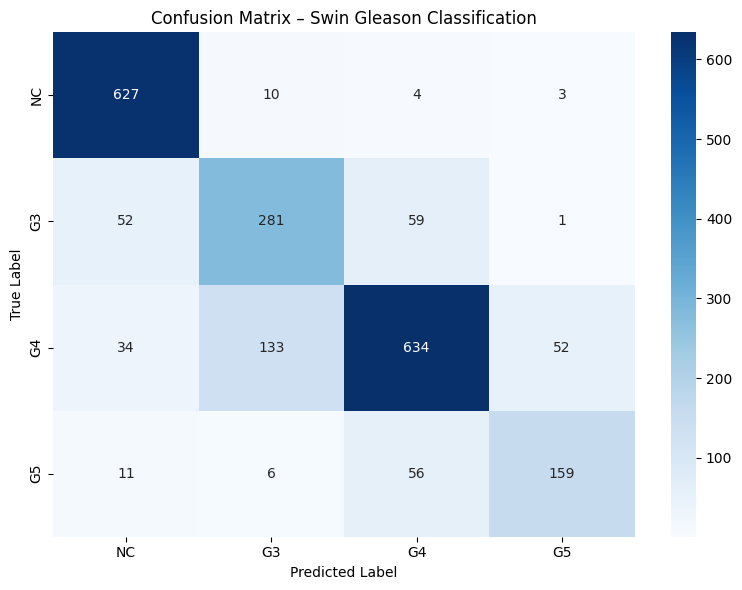

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

class_names = ["NC", "G3", "G4", "G5"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Swin Gleason Classification")
plt.tight_layout()

plt.show()

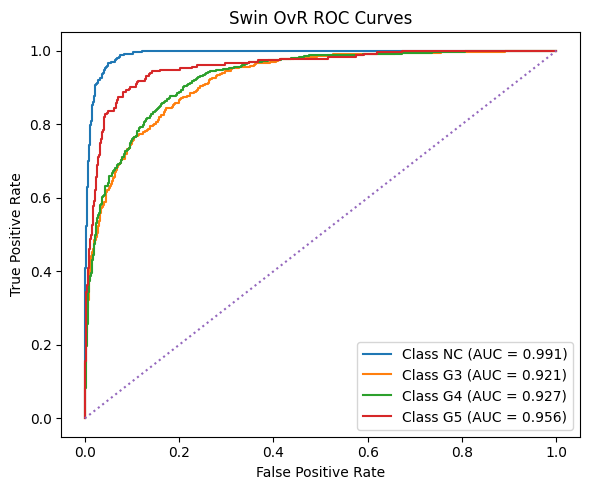

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize - turn the labels into OHE format
num_classes = all_probs.shape[1]
y_true_bin = label_binarize(all_labels, classes=np.arange(num_classes))

plt.figure(figsize=(6, 5))

for c in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, c], all_probs[:, c])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {class_names[c]} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle=":")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Swin OvR ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

          NC     0.8660    0.9736    0.9167       644
          G3     0.6535    0.7150    0.6829       393
          G4     0.8420    0.7433    0.7895       853
          G5     0.7395    0.6853    0.7114       232

    accuracy                         0.8016      2122
   macro avg     0.7753    0.7793    0.7751      2122
weighted avg     0.8032    0.8016    0.7998      2122



In [ ]:
! pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 57.4 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.9 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of mkl-fft to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-random to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-umath to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 110.8 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 82.2 MB/s eta 0:00:00:

In [ ]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget



In [ ]:
cam_model = final_model.model
cam_model.eval()
cam_model.cuda()

target_layers = [cam_model.layers[-1].blocks[-1].norm2]


In [ ]:
def swin_reshape_transform(tensor, height=7, width=7):
    B, N, C = tensor.shape

    if N == height * width + 1:
        tensor = tensor[:, 1:, :]
        N -= 1

    result = tensor.reshape(B, height, width, C)
    result = result.permute(0, 3, 1, 2)  # [B, C, H, W]
    return result

In [ ]:
cam_model = final_model.model
cam_model.eval()
cam_model.cuda()

samples_per_class = {}
class_names = {
    0: "Non Cancerous",
    1: "Gleason 3",
    2: "Gleason 4",
    3: "Gleason 5",
}
num_classes = len(class_names)

# Retrieve one image from each class from the test dataset
with torch.no_grad():
    for imgs, labels, _ in test_loader:
        for i in range(len(labels)):
            lbl = labels[i].item()
            if lbl not in samples_per_class:
                samples_per_class[lbl] = imgs[i]
            if len(samples_per_class) == num_classes:
                break
        if len(samples_per_class) == num_classes:
            break

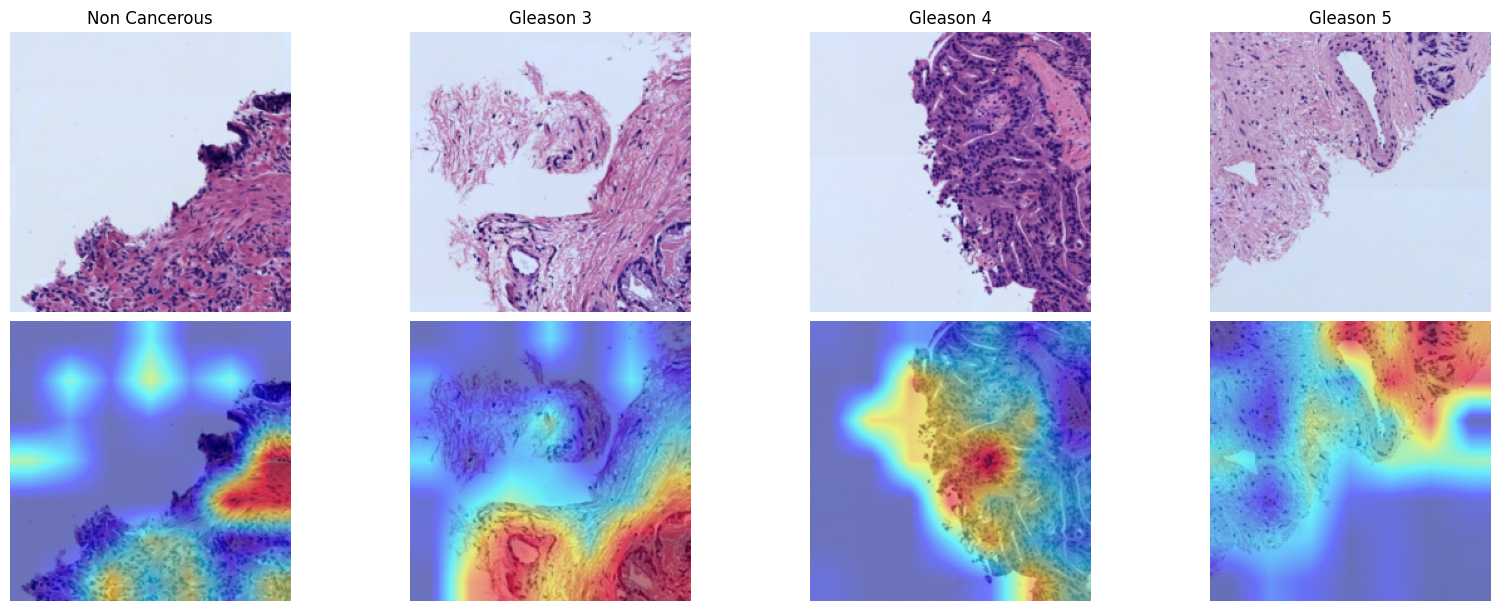

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from pytorch_grad_cam.utils.image import show_cam_on_image

num_classes = len(class_names)

fig, axes = plt.subplots(
    2, num_classes,
    figsize=(4 * num_classes, 6),
    constrained_layout=True
)

with GradCAM(
    model=cam_model,
    target_layers=target_layers,
    reshape_transform=swin_reshape_transform
) as cam:

    for col, label in enumerate(class_names):
        img_tensor = samples_per_class[label]

        img = img_tensor.unsqueeze(0).cuda()
        targets = [ClassifierOutputTarget(label)]

        grayscale_cam = cam(
            input_tensor=img,
            targets=targets
        )[0]

        # Tensor → numpy
        orig_img = img_tensor.permute(1, 2, 0).cpu().numpy()
        orig_img = (orig_img - orig_img.min()) / (orig_img.max() - orig_img.min())

        cam_overlay = show_cam_on_image(
            orig_img,
            grayscale_cam,
            use_rgb=True
        )

        # ---- Top row: Original ----
        axes[0, col].imshow(orig_img)
        axes[0, col].set_title(class_names[label], fontsize=12)
        axes[0, col].axis("off")

        # ---- Bottom row: Grad-CAM ----
        axes[1, col].imshow(cam_overlay)
        axes[1, col].axis("off")

# Row labels
axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Grad-CAM", fontsize=12)

plt.show()

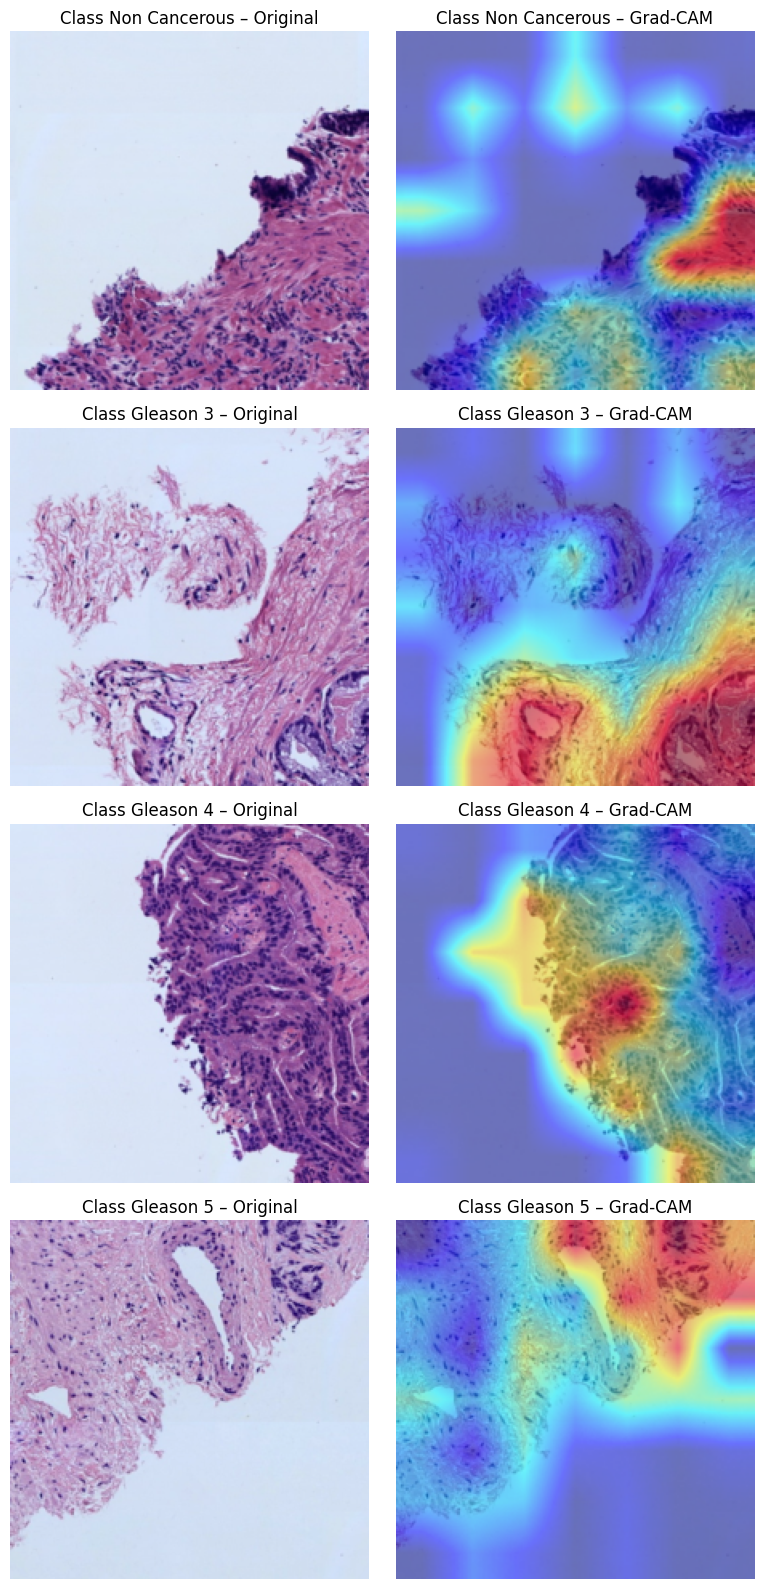

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

ordered_labels = sorted(samples_per_class.keys())

fig, axes = plt.subplots(len(ordered_labels), 2, figsize=(8, 4 * len(ordered_labels)))

with GradCAM(
    model=cam_model,
    target_layers=target_layers,
    reshape_transform=swin_reshape_transform
) as cam:

    for row, label in enumerate(ordered_labels):
        img_tensor = samples_per_class[label]

        img = img_tensor.unsqueeze(0).cuda()
        targets = [ClassifierOutputTarget(label)]

        grayscale_cam = cam(
            input_tensor=img,
            targets=targets
        )[0]

        # Tensor → numpy image
        orig_img = img_tensor.permute(1, 2, 0).cpu().numpy()
        orig_img = (orig_img - orig_img.min()) / (orig_img.max() - orig_img.min())

        cam_overlay = show_cam_on_image(
            orig_img,
            grayscale_cam,
            use_rgb=True
        )

        # Original
        axes[row, 0].imshow(orig_img)
        axes[row, 0].set_title(f"Class {class_names[label]} – Original")
        axes[row, 0].axis("off")

        # Grad-CAM
        axes[row, 1].imshow(cam_overlay)
        axes[row, 1].set_title(f"Class {class_names[label]} – Grad-CAM")
        axes[row, 1].axis("off")

plt.tight_layout()
plt.show()
